# `stochastics.finance.insurance` — claims, premiums and survival

The classic **collective risk model**: claims *arrive* by a counting process and each has a *size*,

$$S(t)=\sum_{i=1}^{N(t)} X_i,\qquad \mathbb E[S(t)]=\mathbb E[N(t)]\;\mathbb E[X].$$

```python
from stochastics.finance import insurance as ins

claims = ins.ClaimProcess(ins.Poisson(rate=120), ins.weibull(shape=1.4, scale=900))
claims.expected_total(T=1)            # E[N] E[X] for one year
A = claims.aggregate(T=1)             # the whole distribution of the year's total
ins.premium_table(A)                  # every premium principle side by side
firm = ins.Company.priced(claims, capital=30_000, principle='std_dev', beta=0.5)
firm.plot()                           # surplus paths, survival curve, ruin vs capital
```

| piece | choices |
|---|---|
| arrivals | `Poisson(rate)` (interarrival times Exp), `Renewal(gap)` (any gap law), `Hawkes(mu, alpha, beta)` (claims cluster) |
| sizes | any frozen `scipy.stats` law; shortcuts `weibull`, `weibull_with_mean`, `lognormal`, `gamma`, `pareto`, `exponential` |
| premium principles | expected value, variance, standard deviation, percentile (VaR), TVaR, exponential, Esscher, proportional hazard, Wang |
| survival | surplus $U(t)=u+ct-S(t)$; ruin is detected *exactly* at claim epochs; Lundberg and Pollaczek–Khinchine for the exact answer |

*Time is in years. Not modelled: interest on the surplus, expenses, reinsurance, dependence between claim sizes.*

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from stochastics.finance import insurance as ins

pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.0f}' if abs(v) >= 1e4 else f'{v:.4g}')

## 1. Arrivals × sizes

120 claims a year on average, Weibull sizes with shape 1.4 (a little lighter than exponential at the very
small end, a longer tail than a normal) and mean 1,000. The expected total is $\mathbb E[N]\,\mathbb E[X]=120{,}000$,
and because the arrivals are Poisson the variance is also exact: $\mathrm{Var}\,S=\lambda\,\mathbb E[X^2]$.

In [2]:
claims = ins.ClaimProcess(ins.Poisson(rate=120), ins.weibull_with_mean(shape=1.4, mean=1000))

print('expected total claims per year  E[N] E[X] =', f'{claims.expected_total(T=1):,.0f}')
var, exact = claims.variance_total(T=1)
print('standard deviation of the year  =', f'{var ** 0.5:,.0f}', '(exact)' if exact else '(approximate)')
claims.loss_ratio_table(1)

expected total claims per year  E[N] E[X] = 120,000
standard deviation of the year  = 13,523 (exact)


E[N]                 120
E[X]                1000
E[S]             120,000
sd[S]             13,523
cv[S]             0.1127
variance exact      True
Name: Poisson(rate=120), weibull_min, dtype: object

**Check by simulation.** `sample` draws whole years of claims (arrival times *and* sizes). The mean of the
yearly totals should match $\mathbb E[N]\mathbb E[X]$, interarrival times should be Exp(120), and the
distribution of the year's total claims is known exactly (FFT of the compound-Poisson characteristic
function), so we can compare the empirical CDF with it.

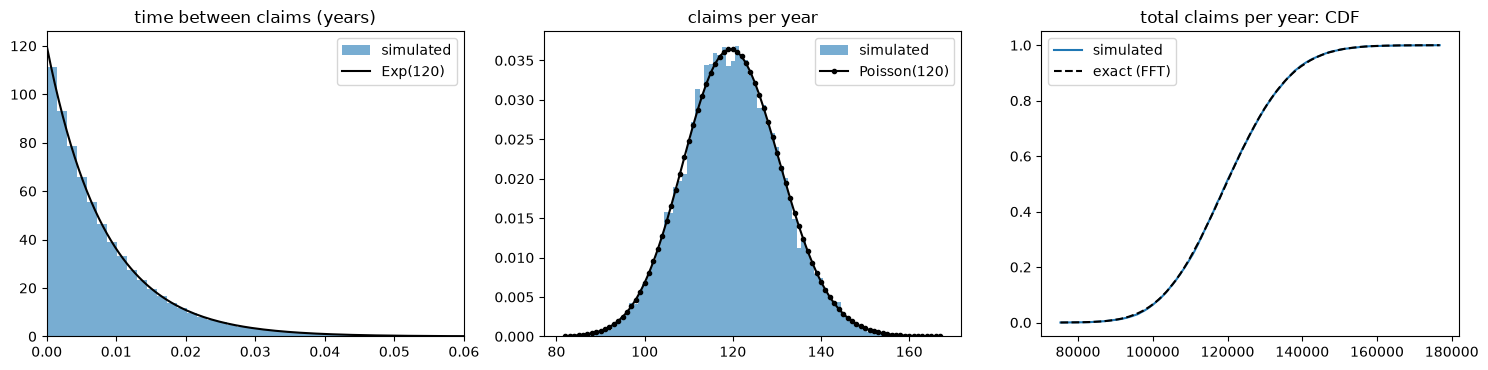

simulated mean 120,032   exact 120,000   E[N]E[X] 120,000


mean        120,000
std          13,523
skew         0.1468
VaR 95%     142,796
VaR 99%     152,894
TVaR 99%    158,056
VaR 99.5%   156,664
Name: Poisson(rate=120) x weibull_min, T=1 (exact pmf), dtype: float64

In [3]:
sample = claims.sample(T=1, n=20_000, seed=1)
A = claims.aggregate(T=1)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
gaps = sample.interarrival()
ax[0].hist(gaps, bins=80, density=True, alpha=.6, label='simulated')
g = np.linspace(0, gaps.max(), 200)
ax[0].plot(g, 120 * np.exp(-120 * g), 'k', label='Exp(120)')
ax[0].set(title='time between claims (years)', xlim=(0, 0.06)); ax[0].legend()

n = sample.counts()
k = np.arange(n.min(), n.max() + 1)
ax[1].hist(n, bins=np.arange(n.min(), n.max() + 2) - .5, density=True, alpha=.6, label='simulated')
ax[1].plot(k, stats.poisson(120).pmf(k), 'k.-', label='Poisson(120)')
ax[1].set(title='claims per year'); ax[1].legend()

tot = np.sort(sample.totals())
ax[2].plot(tot, np.arange(1, len(tot) + 1) / len(tot), label='simulated')
ax[2].plot(tot, A.cdf(tot), 'k--', label='exact (FFT)')
ax[2].set(title='total claims per year: CDF'); ax[2].legend()
plt.tight_layout(); plt.show()

print(f'simulated mean {tot.mean():,.0f}   exact {A.mean:,.0f}   E[N]E[X] {claims.expected_total(1):,.0f}')
A.summary()

## 2. Does the *pattern* of arrivals matter?

Three arrival processes with the **same expected number of claims per year** (120):

* **Poisson** — claims independent, counts have variance = mean.
* **Renewal with Weibull gaps (shape 3)** — claims arrive more regularly than Poisson (variance < mean).
* **Hawkes** — every claim raises the chance of the next for a while (storms, epidemics, aftershocks). Counts have variance well above the mean.

Same mean total claims, very different risk.

In [4]:
sev = ins.weibull_with_mean(shape=1.4, mean=1000)
h0 = ins.Hawkes(mu=60, alpha=10, beta=20)                     # branching ratio alpha/beta = 0.5
hawkes = ins.Hawkes(mu=60 * 120 / h0.mean_count(1), alpha=10, beta=20)   # scale mu so E[N(1)] = 120

arrivals = {
    'Poisson': ins.Poisson(rate=120),
    'Renewal (Weibull gaps, k=3)': ins.Renewal(ins.weibull_with_mean(shape=3, mean=1 / 120)),
    'Hawkes (branching 0.5)': hawkes,
}
rows, aggs = {}, {}
for name, arr in arrivals.items():
    cp = ins.ClaimProcess(arr, sev)
    s = cp.sample(T=1, n=20_000, seed=2)
    n, tot = s.counts(), s.totals()
    rows[name] = {'mean claims': n.mean(), 'var of claims': n.var(), 'Fano (var/mean)': n.var() / n.mean(),
                  'mean total': tot.mean(), 'sd total': tot.std(), 'skew': stats.skew(tot),
                  '99% quantile': np.quantile(tot, .99)}
    aggs[name] = cp.aggregate(T=1, n=40_000, seed=3)
pd.DataFrame(rows).T

,mean claims,var of claims,Fano (var/mean),mean total,sd total,skew,99% quantile
Poisson,120,121.4,1.012,"120,071","13,587",0.1342,"153,241"
"Renewal (Weibull gaps, k=3)",119.5,15.79,0.1321,"119,659",8931,0.1368,"141,548"
Hawkes (branching 0.5),120.1,441,3.672,"120,062","22,436",0.3029,"177,233"


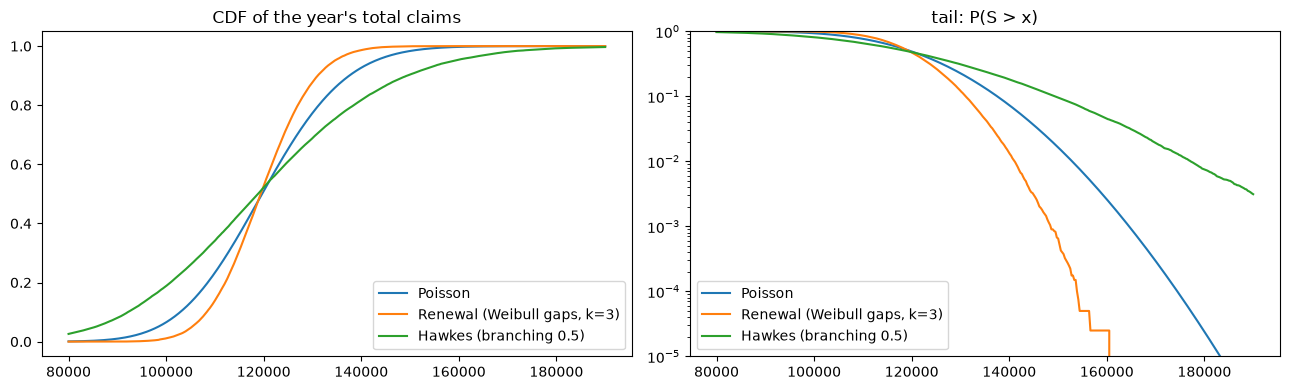

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, cp_agg in aggs.items():
    x = np.linspace(80_000, 190_000, 400)
    ax[0].plot(x, cp_agg.cdf(x), label=name)
    ax[1].plot(x, 1 - cp_agg.cdf(x), label=name)
ax[0].set(title='CDF of the year\'s total claims'); ax[0].legend()
ax[1].set(title='tail: P(S > x)', yscale='log', ylim=(1e-5, 1)); ax[1].legend()
plt.tight_layout(); plt.show()

The means agree; the tails do not. Under a premium principle that charges for variance or tail risk,
clustered claims therefore cost **more** for the same expected loss, and an insurer that ignores clustering
under-prices and over-states its survival.

In [6]:
prem = pd.DataFrame({name: ins.premium_table(a)['premium'] for name, a in aggs.items()})
prem

,Poisson,"Renewal (Weibull gaps, k=3)",Hawkes (branching 0.5)
principle,,,
expected_value,"126,761","124,032","131,200"
variance,"126,761","124,032","131,200"
std_dev,"126,761","124,032","131,200"
percentile,"152,894","141,071","177,205"
tvar,"158,056","144,263","187,073"
exponential,"127,108","124,216","132,538"
esscher,"127,017","124,170","132,174"
proportional_hazard,"125,438","123,145","129,271"
wang,"126,840","124,075","131,470"


## 3. Premium principles

`premium_table(A, base=0.5)` calibrates *every* principle so that its first-order loading is
$0.5\,\mathrm{sd}[S]$. The first three coincide by construction (they differ only in which
statistic they scale), so the interesting differences are in the **tails**: the percentile and TVaR
principles charge for capital to survive the 99th percentile, the exponential and Esscher premiums
weigh the right tail through the moment generating function, and the proportional-hazard premium is the
cheapest here.

* `variance`: $\mathbb E S+\alpha\,\mathrm{Var}\,S$ — the variance premium (what the brief calls the "variance" or "var-squared" principle)
* `std_dev`: $\mathbb E S+\beta\,\mathrm{sd}\,S$
* `percentile`: the $q$-quantile; `tvar`: expected loss beyond it

In [7]:
ins.premium_table(claims.aggregate(T=1))

,parameters,premium,loading,loading in sd
principle,,,,
expected_value,theta=0.05634,"126,761",0.05634,0.5
variance,alpha=3.698e-05,"126,761",0.05634,0.5
std_dev,beta=0.5,"126,761",0.05634,0.5
percentile,q=0.99,"152,894",0.2741,2.433
tvar,q=0.99,"158,056",0.3171,2.814
exponential,a=7.395e-05,"127,108",0.05923,0.5256
esscher,h=3.698e-05,"127,017",0.05848,0.5189
proportional_hazard,rho=1.5,"125,438",0.04532,0.4021
wang,lam=0.5,"126,840",0.057,0.5058


**Heavy tails and the MGF.** The exponential-utility and Esscher premiums are built from the moment generating
function $\mathbb E\,e^{rS}$, which **does not exist** for lognormal, Pareto, or Weibull sizes with shape below 1.
The package says so (`inf`) instead of returning a number that depends on where the simulation stopped.

In [8]:
ln = ins.ClaimProcess(ins.Poisson(120), ins.lognormal(mu=6.4, sigma=1.0))
print('lognormal claims: mean claim size', round(ln.severity.mean()), '| moment generating function exists:', ln.mgf_ok(1e-4), '(lognormal) vs', claims.mgf_ok(1e-4), '(Weibull k=1.4)')
ins.premium_table(ln.aggregate(T=1, n=100_000, seed=1))

lognormal claims: mean claim size 992 | moment generating function exists: False (lognormal) vs True (Weibull k=1.4)


,parameters,premium,loading,loading in sd
principle,,,,
expected_value,theta=0.07525,"128,034",0.07525,0.5
variance,alpha=2.79e-05,"128,034",0.07525,0.5
std_dev,beta=0.5,"128,034",0.07525,0.5
percentile,q=0.99,"166,114",0.3951,2.625
tvar,q=0.99,"175,418",0.4732,3.144
exponential,a=5.58e-05,inf,NaN,NaN
esscher,h=2.79e-05,inf,NaN,NaN
proportional_hazard,rho=1.5,"126,672",0.06382,0.424
wang,lam=0.5,"128,302",0.07751,0.515


## 4. The insurer's survival

An insurer starts with capital $u$ and collects premium at rate $c$:
$U(t)=u+ct-S(t)$. Ruin is the first time $U<0$. Since $U$ only falls at claims, checking just after every claim
is **exact** — no time grid, no missed dips between steps.

`Company.priced(claims, capital, principle, ...)` sets the premium by a principle; `firm.plot()` shows
(1) surplus paths and their 5–95% fan, (2) the survival curve $P(\text{not ruined by } t)$ with a confidence band
and the infinite-horizon Pollaczek–Khinchine level, (3) ruin probability against starting capital — Monte-Carlo
against the exact bracket and the Lundberg bound — and (4) the distribution of one year's claims against the premium and VaR.

premium rate 126,761/yr   safety loading 5.63%   claims/yr 120
Lundberg adjustment coefficient R = 7.051e-05


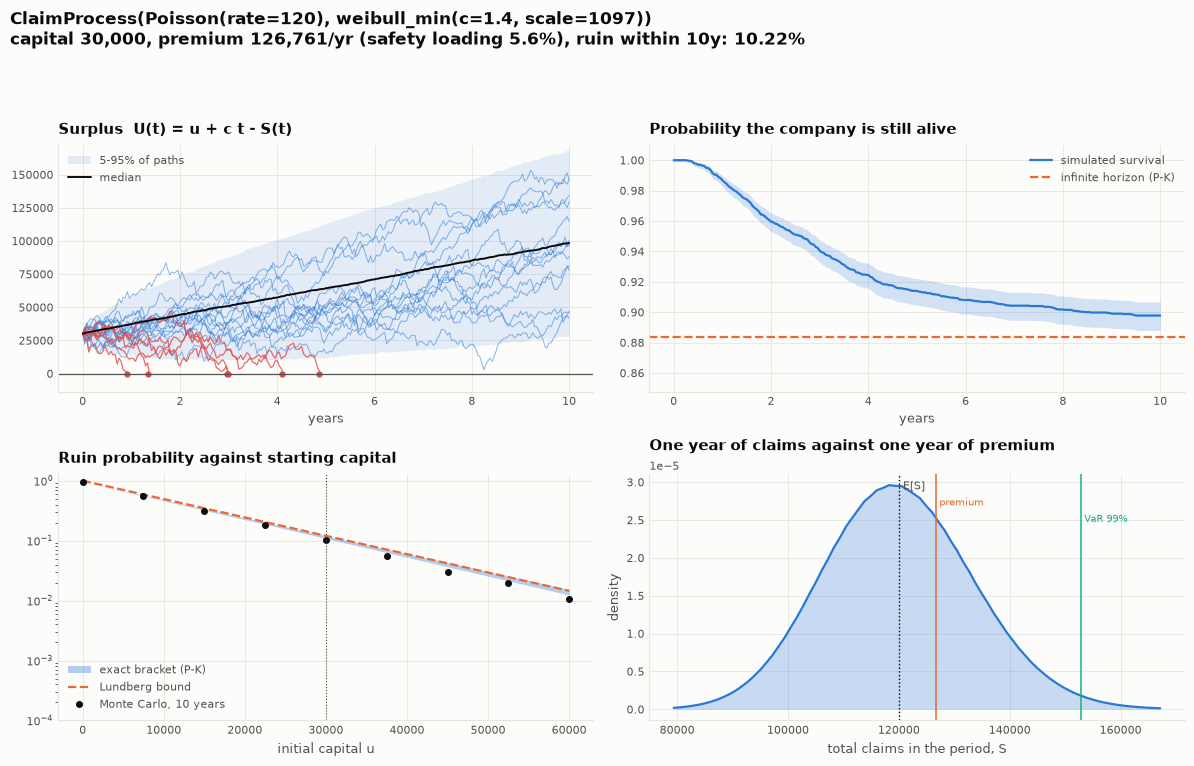

In [9]:
firm = ins.Company.priced(claims, capital=30_000, principle='std_dev', beta=0.5)
print(f'premium rate {firm.premium_rate:,.0f}/yr   safety loading {firm.safety_loading:.2%}   claims/yr {firm.claim_rate:,.0f}')
print('Lundberg adjustment coefficient R =', f'{firm.adjustment_coefficient():.3e}')
firm.plot(horizon=10, n=4000, seed=1)

In [10]:
res = firm.simulate(horizon=10, n=4000, seed=1)
res.summary()

paths                 4000
horizon                 10
ruin probability    0.1022
ci low             0.09324
ci high              0.112
median ruin time      2.66
claims per year        120
dtype: float64

**Exact ruin probabilities.** For Poisson arrivals the infinite-horizon ruin probability is the
Pollaczek–Khinchine geometric sum over ladder heights. `ruin_exact` discretises the ladder-height law in
two ways (rounding up and down) and Panjer-recurses each, so the true value lies **between** `lower` and
`upper`. The Lundberg bound $e^{-Ru}$ is an upper bound that is tight for large $u$. The Monte-Carlo column is
a 25-year horizon with a 95% confidence interval, so it can sit slightly *below* the infinite-horizon answer.

In [11]:
u = np.array([0, 10e3, 20e3, 30e3, 45e3, 60e3])
exact = firm.ruin_exact(u)
mc = []
for i, x in enumerate(u):
    r = ins.Company(claims, capital=float(x), premium_rate=firm.premium_rate).simulate(horizon=25, n=4000, seed=10 + i)
    p = r.ruin_probability()
    mc.append((p, *r.interval(p)))
exact[['MC, 25 years', 'MC low', 'MC high']] = mc
exact

,lower,upper,lundberg,"MC, 25 years",MC low,MC high
u,,,,,,
0,0.9459,0.9467,1,0.947,0.9396,0.9535
"10,000",0.4674,0.4744,0.494,0.4615,0.4461,0.477
"20,000",0.2293,0.236,0.2441,0.238,0.2251,0.2514
"30,000",0.1125,0.1174,0.1206,0.1163,0.1067,0.1266
"45,000",0.03865,0.0412,0.04187,0.03775,0.03227,0.04411
"60,000",0.01328,0.01446,0.01454,0.0135,0.01036,0.01757


## 5. What does the premium principle do to survival?

Same claims, same starting capital (30,000), and a premium set by each principle. The first-order-loading
principles all charge about the same, so their survival is about the same; the quantile-based premiums
charge 27-32% more and the insurer essentially never fails. The proportional-hazard premium is the cheapest
and the least safe. `compare_principles` uses common random numbers
(the same claim histories for every principle), so the differences are not noise.

In [12]:
cmp = ins.compare_principles(claims, capital=30_000, horizon=10, n=4000, seed=1)
cmp

,parameters,premium,loading,ruin probability,ci low,ci high
principle,,,,,,
expected_value,theta=0.05634,"126,761",0.05634,0.1022,0.09324,0.112
variance,alpha=3.698e-05,"126,761",0.05634,0.1022,0.09324,0.112
std_dev,beta=0.5,"126,761",0.05634,0.1022,0.09324,0.112
percentile,q=0.99,"152,894",0.2741,0,0,0.0009595
tvar,q=0.99,"158,056",0.3171,0,0,0.0009595
exponential,a=7.395e-05,"127,108",0.05923,0.0935,0.08486,0.1029
esscher,h=3.698e-05,"127,017",0.05848,0.095,0.0863,0.1045
proportional_hazard,rho=1.5,"125,438",0.04532,0.146,0.1354,0.1573
wang,lam=0.5,"126,840",0.057,0.1003,0.09132,0.1099


## 6. Heavier tails cost survival

Hold the **mean claim and the premium fixed** (set by the standard-deviation principle for the Weibull k=1.4 case)
and make the claim sizes heavier-tailed (shape 0.6) or lighter (shape 3). Same expected loss and same income, very
different survival: ruin is a tail event.

In [13]:
rate = firm.premium_rate
rows = {}
for k in (0.6, 1.0, 1.4, 3.0):
    cp = ins.ClaimProcess(ins.Poisson(120), ins.weibull_with_mean(k, 1000))
    co = ins.Company(cp, capital=30_000, premium_rate=rate)
    r = co.simulate(horizon=10, n=4000, seed=5)
    p = r.ruin_probability()
    lo, hi = r.interval(p)
    rows[f'Weibull k={k}'] = {'sd of annual claims': cp.variance_total(1)[0] ** .5,
                              'ruin P (10y)': p, '95% CI low': lo, '95% CI high': hi}
pd.DataFrame(rows).T

,sd of annual claims,ruin P (10y),95% CI low,95% CI high
Weibull k=0.6,"22,156",0.368,0.3532,0.3831
Weibull k=1.0,"15,492",0.1603,0.1492,0.1719
Weibull k=1.4,"13,523",0.09375,0.0851,0.1032
Weibull k=3.0,"11,656",0.0465,0.0404,0.05347


## Next steps / ideas

* **Reinsurance** — excess-of-loss or quota-share layers inside `Company` (the surplus equation just changes).
* **Interest and dividends** — a barrier strategy: pay out surplus above a level, and ask for the expected discounted dividends *and* the ruin time.
* **Dependence** — claims whose sizes share a common factor, or a Hawkes process whose *marks* (sizes) excite it.
* **Link to the markets** — an insurer that invests its surplus in one of the stochastic markets of `finance.market`.